# 02 — Logistic Regression Baseline

**目的：** 用最簡單的模型立一個可比較的基準（baseline），之後的 random forest／XGBoost 全部同佢比。

**方法（骨架規定）：**
- 切分：分層抽樣（stratify）分訓練／測試集 80／20，固定 `random_state=42`，之後所有模型共用同一個測試集。
- 編碼：類別欄位 one-hot；數值欄位標準化。
- 評估：AUC、recall（違約類）、precision（違約類）、混淆矩陣、accuracy。**準確率只作參考，必須與上面指標並列**——違約是少數類別（約 22%），全猜無違約都有高準確率但零價值。
- 分類門檻：預設 0.5。調門檻就是在 recall 和 precision 之間取捨，這正是 Credit Risk 面試的核心追問之一。

## 0. 讀入特徵表

讀入 `01_eda.ipynb` 產出的 `credit_features.csv`，先核對形狀、型態、缺失，與 SQL 驗證結果對照。

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, confusion_matrix, precision_score,
                             recall_score, roc_auc_score)
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

RAW_NAME = "default of credit card clients.xls"

from pathlib import Path

# 找出項目根目錄：不論由 notebooks/ 還是項目根目錄執行都 work
_CANDIDATES = [Path.cwd(), Path.cwd().parent]
PROJECT_ROOT = next(
    (p for p in _CANDIDATES if (p / "data" / "raw" / RAW_NAME).exists()),
    Path.cwd().parent,
)
RAW_PATH = PROJECT_ROOT / "data" / "raw" / RAW_NAME
PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"
REPORTS_DIR = PROJECT_ROOT / "reports"
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)
REPORTS_DIR.mkdir(parents=True, exist_ok=True)
print("項目根目錄：", PROJECT_ROOT)
print("原始檔：", RAW_PATH, "存在：" , RAW_PATH.exists())

項目根目錄： /home/hatch/workspace/goals/credit-default-prediction-portfolio-project/files/credit-default-project
原始檔： /home/hatch/workspace/goals/credit-default-prediction-portfolio-project/files/credit-default-project/data/raw/default of credit card clients.xls 存在： True


In [2]:
features = pd.read_csv(PROCESSED_DIR / "credit_features.csv")
print("形狀（行，欄）：", features.shape)
print("缺失值總數：", int(features.isna().sum().sum()))
print("目標違約率：", round(features["default_payment_next_month"].mean() * 100, 2), "%")
features.head(3)

形狀（行，欄）： (30000, 34)
缺失值總數： 3669
目標違約率： 22.12 %


,ID,LIMIT_BAL,SEX,education_code,education_label,marriage_code,marriage_label,AGE,BILL_AMT1,BILL_AMT2,...,pay_5_delay_months,pay_6_delay_months,default_payment_next_month,utilisation_1,pay_ratio_1,pay_ratio_avg,max_delay_6m,delay_months_cnt,consecutive_delay,bill_trend
0,1,20000,2,2,University,1,Married,24,3913,3102,...,0,0,1,0.195650,0.000000,0.089434,2,2,2,3913
1,2,120000,2,2,University,2,Single,26,2682,1725,...,0,2,1,0.022350,0.000000,0.292791,2,2,0,-579
2,3,90000,2,2,University,2,Single,34,29239,14027,...,0,0,0,0.324878,0.051917,0.108388,0,0,0,13690


## 1. 特徵與切分

- 數值特徵：信用額度、年齡、6 個月結單／還款金額、6 個延遲月數，以及 01 號筆記本的 7 個衍生欄位。
- 類別特徵：性別、教育程度標籤、婚姻狀況標籤（未知類別已按骨架合併）。
- 比率欄位的缺失（分母 ≤ 0 的個案）用中位數填補——**此處只為跑通 baseline**；正式做法應在 SQL 層先處理，見骨架 C 部分。
- 分層 80／20 切分，`random_state=42`，訓練集與測試集的違約率應該接近。

In [3]:
numeric_features = (
    ["LIMIT_BAL", "AGE"]
    + [f"BILL_AMT{i}" for i in range(1, 7)]
    + [f"PAY_AMT{i}" for i in range(1, 7)]
    + ["pay_0_delay_months", "pay_2_delay_months", "pay_3_delay_months",
       "pay_4_delay_months", "pay_5_delay_months", "pay_6_delay_months"]
    + ["utilisation_1", "pay_ratio_1", "pay_ratio_avg", "max_delay_6m",
       "delay_months_cnt", "consecutive_delay", "bill_trend"]
)
categorical_features = ["SEX", "education_label", "marriage_label"]

X = features[numeric_features + categorical_features].copy()
y = features["default_payment_next_month"]

# 比率欄位缺失用中位數填補（只為跑通 baseline；正式處理見骨架）
for col in ["utilisation_1", "pay_ratio_1", "pay_ratio_avg"]:
    X[col] = X[col].fillna(X[col].median())

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=42)
print(f"訓練集：{len(X_train):,} 行，違約率 {y_train.mean() * 100:.2f}%")
print(f"測試集：{len(X_test):,} 行，違約率 {y_test.mean() * 100:.2f}%")
print(f"特徵數：{X.shape[1]}（數值 {len(numeric_features)} + 類別 {len(categorical_features)}）")

訓練集：24,000 行，違約率 22.12%
測試集：6,000 行，違約率 22.12%
特徵數：30（數值 27 + 類別 3）


## 2. Baseline：Logistic Regression

Pipeline：數值標準化 → 類別 one-hot → logistic regression（`max_iter=1000`）。

測試集指標（門檻 0.5）：
  AUC: 0.7481
  Recall (default): 0.3617
  Precision (default): 0.6575
  Accuracy: 0.8172

混淆矩陣（行 = 真實，欄 = 預測；0 = 無違約，1 = 違約）：
      預測 0  預測 1
真實 0  4423   250
真實 1   847   480


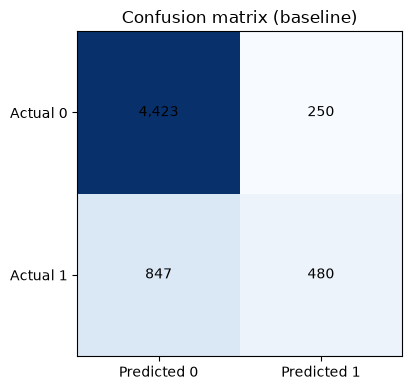

In [4]:
preprocess = ColumnTransformer([
    ("num", StandardScaler(), numeric_features),
    ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False),
     categorical_features),
])
model = Pipeline([
    ("preprocess", preprocess),
    ("clf", LogisticRegression(max_iter=1000, random_state=42)),
])
model.fit(X_train, y_train)

y_pred = model.predict(X_test)
y_proba = model.predict_proba(X_test)[:, 1]

metrics = {
    "AUC": roc_auc_score(y_test, y_proba),
    "Recall (default)": recall_score(y_test, y_pred),
    "Precision (default)": precision_score(y_test, y_pred),
    "Accuracy": accuracy_score(y_test, y_pred),
}
print("測試集指標（門檻 0.5）：")
for k, v in metrics.items():
    print(f"  {k}: {v:.4f}")

cm = confusion_matrix(y_test, y_pred)
print()
print("混淆矩陣（行 = 真實，欄 = 預測；0 = 無違約，1 = 違約）：")
print(pd.DataFrame(cm, index=["真實 0", "真實 1"], columns=["預測 0", "預測 1"]).to_string())

fig, ax = plt.subplots(figsize=(4.5, 4))
ax.imshow(cm, cmap="Blues")
ax.set_xticks([0, 1]); ax.set_yticks([0, 1])
ax.set_xticklabels(["Predicted 0", "Predicted 1"])
ax.set_yticklabels(["Actual 0", "Actual 1"])
ax.set_title("Confusion matrix (baseline)")
for i in range(2):
    for j in range(2):
        ax.text(j, i, f"{cm[i, j]:,}", ha="center", va="center")
plt.tight_layout()
plt.show()

## 3. 係數方向檢查：是否與常識一致？

睇最大正／負係數的特徵：延遲相關欄位（例如 `max_delay_6m`、`consecutive_delay`）係數應該係正（延遲愈多，違約機會愈高）；還款比率愈高，係數應該係負。如果方向倒轉，先懷疑編碼或特徵定義，唔好照單全收。

絕對值最大的 12 個係數：
                              feature  coefficient
cat__education_label_Others / Unknown    -0.943664
                num__delay_months_cnt     0.853889
                           cat__SEX_2    -0.471297
              num__pay_0_delay_months     0.468085
           cat__marriage_label_Single    -0.345216
                           cat__SEX_1    -0.337113
 cat__marriage_label_Others / Unknown    -0.265822
                       num__LIMIT_BAL    -0.210649
               num__consecutive_delay    -0.208839
          cat__marriage_label_Married    -0.197372
                    num__max_delay_6m     0.195835
              num__pay_2_delay_months    -0.169673


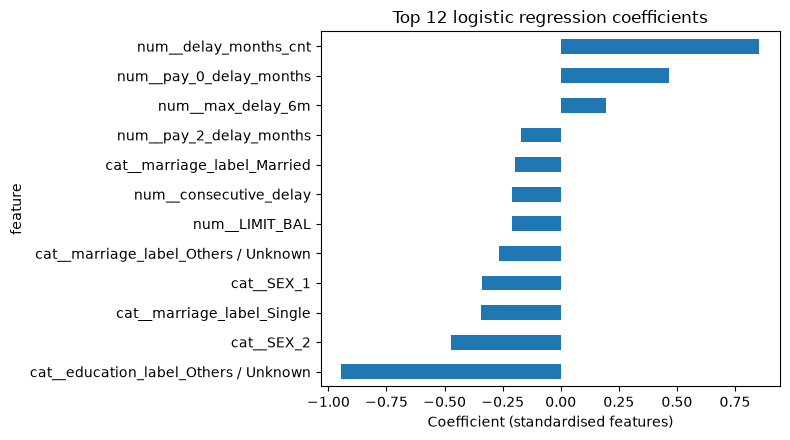

In [5]:
feature_names = model.named_steps["preprocess"].get_feature_names_out()
coefs = model.named_steps["clf"].coef_[0]
coef_df = pd.DataFrame({"feature": feature_names, "coefficient": coefs})
coef_df["abs_coef"] = coef_df["coefficient"].abs()
top = coef_df.sort_values("abs_coef", ascending=False).head(12).drop(columns="abs_coef")
print("絕對值最大的 12 個係數：")
print(top.to_string(index=False))

ax = top.sort_values("coefficient").plot(kind="barh", x="feature", y="coefficient",
                                         figsize=(8, 4.5), legend=False)
ax.set_title("Top 12 logistic regression coefficients")
ax.set_xlabel("Coefficient (standardised features)")
plt.tight_layout()
plt.show()

## 4. 類別不平衡比較：`class_weight='balanced'`（骨架第 4 步）

只試一至兩種處理並比較，寫低試過甚麼、效果如何，不要堆砌方法。`balanced` 通常會提高 recall（捉到更多真違約者），代價是 precision 下降（更多誤報）。

In [6]:
balanced = Pipeline([
    ("preprocess", ColumnTransformer([
        ("num", StandardScaler(), numeric_features),
        ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False),
         categorical_features),
    ])),
    ("clf", LogisticRegression(max_iter=1000, class_weight="balanced", random_state=42)),
])
balanced.fit(X_train, y_train)
y_pred_b = balanced.predict(X_test)
y_proba_b = balanced.predict_proba(X_test)[:, 1]

metrics_b = {
    "AUC": roc_auc_score(y_test, y_proba_b),
    "Recall (default)": recall_score(y_test, y_pred_b),
    "Precision (default)": precision_score(y_test, y_pred_b),
    "Accuracy": accuracy_score(y_test, y_pred_b),
}
comparison = pd.DataFrame({"Baseline": metrics, "class_weight=balanced": metrics_b})
print("測試集指標比較（門檻 0.5）：")
print(comparison.round(4).to_string())
print()
print("解讀：balanced 版 recall 上升、precision 下降，是預期中的取捨；")
print("揀邊個取決於業務成本：漏捉違約者 = 直接信貸損失，誤報 = 審批成本。")

測試集指標比較（門檻 0.5）：
                     Baseline  class_weight=balanced
AUC                    0.7481                 0.7486
Recall (default)       0.3617                 0.5848
Precision (default)    0.6575                 0.4491
Accuracy               0.8172                 0.7495

解讀：balanced 版 recall 上升、precision 下降，是預期中的取捨；
揀邊個取決於業務成本：漏捉違約者 = 直接信貸損失，誤報 = 審批成本。


## 5. 寫出模型結果表

存入 `reports/model_results.csv`，Power BI 第三頁直接讀這張表，確保數字一致。骨架文件入面的模型結果表，請用呢度跑出的真實數字填寫。

In [7]:
results = pd.DataFrame([
    {"模型": "Logistic regression (baseline)", **metrics,
     "備註": "threshold 0.5; stratified 80/20, random_state=42"},
    {"模型": "Logistic regression (class_weight=balanced)", **metrics_b,
     "備註": "threshold 0.5; stratified 80/20, random_state=42"},
])
results_path = REPORTS_DIR / "model_results.csv"
results.to_csv(results_path, index=False)
print("已存入：", results_path)
print(results.round(4).to_string(index=False))

已存入： /home/hatch/workspace/goals/credit-default-prediction-portfolio-project/files/credit-default-project/reports/model_results.csv
                                         模型    AUC  Recall (default)  Precision (default)  Accuracy                                               備註
             Logistic regression (baseline) 0.7481            0.3617               0.6575    0.8172 threshold 0.5; stratified 80/20, random_state=42
Logistic regression (class_weight=balanced) 0.7486            0.5848               0.4491    0.7495 threshold 0.5; stratified 80/20, random_state=42


## 下一步

- `03_tree_models.ipynb`（待做）：random forest，之後有時間先試 XGBoost；調參只做小範圍，不要為追分數過度調參。記住：三個模型共用同一個測試集（`random_state=42` 的分層切分），指標先至可以直接比較。
- 門檻取捨：預設 0.5 不一定適合不平衡數據；可以試下調門檻對 recall／precision 的影響，寫低你揀邊個門檻、點解。